# Machine Learning - 1  

Subject: 6-Layer Decoder-Only Transformer for Shakespeare Text Generation

Name : Lucie Huang


## 1. Imports and Environment Setup


In [23]:
import os
import math
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import AutoTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Using device: cpu


## 2. Dataset Loading

The text is split into:

- 90% training data
- 10% validation data


In [24]:
# Download TinyShakespeare dataset

data_url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
data_path = "tinyshakespeare.txt"


response = requests.get(data_url)
response.raise_for_status()
with open(data_path, "w", encoding="utf-8") as f:
    f.write(response.text)

with open(data_path, "r", encoding="utf-8") as f:
    text = f.read()

# Train / validation split
n = len(text)
train_text = text[:int(0.9 * n)]
val_text = text[int(0.9 * n):]



## 3. Tokenization with a LLaMA-Compatible Tokenizer
 
Here, the tokenizer from `TinyLlama/TinyLlama-1.1B-Chat-v1.0` is used.

In [25]:
tokenizer = AutoTokenizer.from_pretrained("TinyLlama/TinyLlama-1.1B-Chat-v1.0")

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.model_max_length = int(1e12)

vocab_size = tokenizer.vocab_size

print("Vocabulary size:", vocab_size)

train_ids = tokenizer.encode(train_text, add_special_tokens=False)
val_ids = tokenizer.encode(val_text, add_special_tokens=False)

train_ids = torch.tensor(train_ids, dtype=torch.long)
val_ids = torch.tensor(val_ids, dtype=torch.long)


Vocabulary size: 32000


## 4. Hyperparameters

A compact model is used because the dataset is small and the training is performed on limited local hardware.  


In [26]:
batch_size = 4
block_size = 64
d_model = 128
n_heads = 4
n_layers = 6
dropout = 0.1

learning_rate = 3e-4
max_iters = 1000
eval_interval = 100
eval_iters = 20

ffn_hidden_dim = 4 * d_model

assert d_model % n_heads == 0, "d_model must be divisible by n_heads."


## 5. Batch Creation for Autoregressive Training

The model is trained using next-token prediction.

For each sequence:

- `x` contains tokens from position `t` to `t + block_size - 1`
- `y` contains the next tokens from position `t + 1` to `t + block_size`

given previous tokens, predict the next token


In [27]:
def get_batch(split):
    """
    Create one batch of input tokens x and target tokens y.
    y is x shifted by one token.
    """
    data = train_ids if split == "train" else val_ids

    ix = torch.randint(0, len(data) - block_size - 1, (batch_size,))

    x = torch.stack([data[i:i + block_size] for i in ix])
    y = torch.stack([data[i + 1:i + block_size + 1] for i in ix])

    x = x.to(device)
    y = y.to(device)

    return x, y


# 6. Model Implementation

The architecture is:

```text
Token IDs
→ Token Embedding
→ 6 × Transformer Decoder Blocks
    → LayerNorm
    → Masked Multi-Head Self-Attention with RoPE
    → Residual Connection
    → LayerNorm
    → Feed-Forward Network
    → Residual Connection
→ Final LayerNorm
→ Output Projection
→ Next-token logits
```

The model is decoder-only because it uses causal masking and predicts future tokens one at a time.


## 6.1 Rotary Positional Embedding (RoPE)

A transformer has no recurrence, so it needs some way to represent token order.  

RoPE is applied inside attention to the query and key vectors.  
Instead of adding a position vector to the token embedding, RoPE rotates pairs of query/key dimensions according to their token positions.

This allows attention to use positional information while keeping the model decoder-only and autoregressive.


In [28]:
class RotaryEmbedding(nn.Module):
    """
    Rotary Positional Embedding for attention queries and keys.
    Input shape: [batch, heads, seq_len, head_dim]
    Output shape: [batch, heads, seq_len, head_dim]
    """

    def __init__(self, dim, max_seq_len=2048, base=10000):
        super().__init__()

        assert dim % 2 == 0, "RoPE head dimension must be even."

        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))
        positions = torch.arange(max_seq_len).float()
        freqs = torch.outer(positions, inv_freq)

        self.register_buffer("cos", torch.cos(freqs), persistent=False)
        self.register_buffer("sin", torch.sin(freqs), persistent=False)

    def forward(self, x):
        batch_size, n_heads, seq_len, head_dim = x.shape

        cos = self.cos[:seq_len].to(x.device)
        sin = self.sin[:seq_len].to(x.device)

        x_even = x[..., 0::2]
        x_odd = x[..., 1::2]

        x_rotated_even = x_even * cos - x_odd * sin
        x_rotated_odd = x_even * sin + x_odd * cos

        x_out = torch.empty_like(x)
        x_out[..., 0::2] = x_rotated_even
        x_out[..., 1::2] = x_rotated_odd

        return x_out


## 6.2 Masked Multi-Head Self-Attention

In [29]:
class MaskedMultiHeadSelfAttention(nn.Module):
    """
    Causal multi-head self-attention with RoPE applied to Q and K.
    """

    def __init__(self, d_model, n_heads, block_size, dropout=0.1):
        super().__init__()

        assert d_model % n_heads == 0

        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

        self.rope = RotaryEmbedding(self.head_dim, max_seq_len=block_size)

        mask = torch.tril(torch.ones(block_size, block_size))
        self.register_buffer(
            "causal_mask",
            mask.view(1, 1, block_size, block_size),
            persistent=False
        )

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

    def forward(self, x):
        batch_size, seq_len, d_model = x.shape

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        q = q.view(batch_size, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, seq_len, self.n_heads, self.head_dim).transpose(1, 2)

        q = self.rope(q)
        k = self.rope(k)

        attn_scores = q @ k.transpose(-2, -1)
        attn_scores = attn_scores / math.sqrt(self.head_dim)

        mask = self.causal_mask[:, :, :seq_len, :seq_len]
        attn_scores = attn_scores.masked_fill(mask == 0, float("-inf"))

        attn_weights = F.softmax(attn_scores, dim=-1)
        attn_weights = self.attn_dropout(attn_weights)

        out = attn_weights @ v
        out = out.transpose(1, 2).contiguous().view(batch_size, seq_len, d_model)

        out = self.out_proj(out)
        out = self.resid_dropout(out)

        return out


## 6.3 Feed-Forward Network (FFN)

The FFN is applied independently to each token position.  
It first expands the representation from `d_model` to `4 × d_model`, applies a nonlinearity, and then projects the result back to `d_model`.

This gives the model additional capacity beyond attention.


In [30]:
class FeedForwardNetwork(nn.Module):
    """
    Standard transformer feed-forward network.
    """

    def __init__(self, d_model, hidden_dim, dropout=0.1):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(d_model, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


## 6.4 Transformer Decoder Block


In [31]:
class TransformerBlock(nn.Module):
    """
    One decoder-only transformer block.
    """

    def __init__(self, d_model, n_heads, block_size, ffn_hidden_dim, dropout=0.1):
        super().__init__()

        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MaskedMultiHeadSelfAttention(
            d_model=d_model,
            n_heads=n_heads,
            block_size=block_size,
            dropout=dropout
        )

        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForwardNetwork(
            d_model=d_model,
            hidden_dim=ffn_hidden_dim,
            dropout=dropout
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x


## 6.5 Full 6-Layer Decoder-Only Transformer

The output head is tied to the token embedding matrix.  
Weight tying reduces the parameter count and is often used in language models.


In [32]:
class DecoderOnlyTransformer(nn.Module):
    """
    A 6-layer decoder-only transformer for autoregressive language modeling.
    """

    def __init__(
        self,
        vocab_size,
        d_model,
        n_heads,
        n_layers,
        block_size,
        ffn_hidden_dim,
        dropout=0.1
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.d_model = d_model
        self.n_heads = n_heads
        self.n_layers = n_layers
        self.block_size = block_size

        self.token_embedding = nn.Embedding(vocab_size, d_model)

        self.blocks = nn.ModuleList([
            TransformerBlock(
                d_model=d_model,
                n_heads=n_heads,
                block_size=block_size,
                ffn_hidden_dim=ffn_hidden_dim,
                dropout=dropout
            )
            for _ in range(n_layers)
        ])

        self.final_ln = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)

        self.lm_head.weight = self.token_embedding.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        batch_size, seq_len = idx.shape

        assert seq_len <= self.block_size, "Sequence length exceeds block size."

        x = self.token_embedding(idx)

        for block in self.blocks:
            x = block(x)

        x = self.final_ln(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, self.vocab_size),
                targets.reshape(-1)
            )

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        """
        Generate text autoregressively.
        """
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]

            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                values, _ = torch.topk(logits, top_k)
                min_values = values[:, -1].unsqueeze(1)
                logits = logits.masked_fill(logits < min_values, float("-inf"))

            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)

        return idx


## 6.6 Model Creation and Sanity Check


In [33]:
model = DecoderOnlyTransformer(
    vocab_size=vocab_size,
    d_model=d_model,
    n_heads=n_heads,
    n_layers=n_layers,
    block_size=block_size,
    ffn_hidden_dim=ffn_hidden_dim,
    dropout=dropout
).to(device)

x, y = get_batch("train")
logits, loss = model(x, y)

print(model)
print("Logits shape:", logits.shape)
print("Initial loss:", loss.item())


DecoderOnlyTransformer(
  (token_embedding): Embedding(32000, 128)
  (blocks): ModuleList(
    (0-5): 6 x TransformerBlock(
      (ln1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MaskedMultiHeadSelfAttention(
        (q_proj): Linear(in_features=128, out_features=128, bias=False)
        (k_proj): Linear(in_features=128, out_features=128, bias=False)
        (v_proj): Linear(in_features=128, out_features=128, bias=False)
        (out_proj): Linear(in_features=128, out_features=128, bias=False)
        (rope): RotaryEmbedding()
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ffn): FeedForwardNetwork(
        (net): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=512, out_features=128, bias=True)

# 7. Parameter Count Analysis

This section computes the number of trainable parameters in two ways:

1. Experimental count: directly from PyTorch using `model.named_parameters()`
2. Theoretical count: using formulas for each component of the architecture

Because the output head is tied to the token embedding matrix, it does not add an extra independent parameter matrix.


In [34]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

param_rows = []

for name, param in model.named_parameters():
    param_rows.append({
        "Layer": name,
        "Shape": tuple(param.shape),
        "Parameters": param.numel()
    })

param_df = pd.DataFrame(param_rows)
param_df


Total parameters: 5,282,816
Trainable parameters: 5,282,816


,Layer,Shape,Parameters
0,token_embedding.weight,"(32000, 128)",4096000
1,blocks.0.ln1.weight,"(128,)",128
2,blocks.0.ln1.bias,"(128,)",128
3,blocks.0.attn.q_proj.weight,"(128, 128)",16384
4,blocks.0.attn.k_proj.weight,"(128, 128)",16384
...,...,...,...
70,blocks.5.ffn.net.0.bias,"(512,)",512
71,blocks.5.ffn.net.2.weight,"(128, 512)",65536
72,blocks.5.ffn.net.2.bias,"(128,)",128
73,final_ln.weight,"(128,)",128


The largest parameter contribution comes from the token embedding layer. Since the LLaMA-compatible tokenizer has a vocabulary size of 32,000 and the model dimension is 128, the embedding layer contains:

32,000 × 128 = 4,096,000 parameters

This means that most of the model parameters are used to represent vocabulary tokens. This is expected when using a subword tokenizer with a large vocabulary.

Each transformer block contains LayerNorm parameters, masked self-attention projections, and feed-forward network parameters. The attention module uses four projection matrices: Q, K, V, and output projection. Each projection has shape 128 × 128, giving 16,384 parameters per projection.

The feed-forward network expands the hidden dimension from 128 to 512 and then projects it back to 128. This makes the FFN one of the major parameter contributors inside each transformer block.

Overall, the model has approximately 5.28 million parameters. This is small compared with modern large language models, but it is appropriate for this assignment because it satisfies the 6-layer transformer requirement while remaining feasible to train on CPU or limited laptop hardware.

## 7.1 Theoretical Parameter Count

Let:

- `V` = vocabulary size
- `D` = model dimension
- `L` = number of transformer layers
- `F` = FFN hidden dimension

Parameter formulas:

### Token embedding

```text
V × D
```

### Attention per block

The attention block has four projection matrices:

```text
Q: D × D
K: D × D
V: D × D
Output: D × D
```

So:

```text
Attention parameters per block = 4D²
```

### FFN per block

The FFN contains two linear layers:

```text
D → F → D
```

With biases:

```text
D × F + F + F × D + D
```


In [35]:
V = vocab_size
D = d_model
L = n_layers
F_hidden = ffn_hidden_dim

embedding_params = V * D
attention_params_per_block = 4 * D * D
ffn_params_per_block = (D * F_hidden + F_hidden) + (F_hidden * D + D)
layernorm_params_per_block = 4 * D

params_per_block = (
    attention_params_per_block
    + ffn_params_per_block
    + layernorm_params_per_block
)

all_blocks_params = L * params_per_block
final_ln_params = 2 * D
output_head_params = 0  # tied with token_embedding

theoretical_total = (
    embedding_params
    + all_blocks_params
    + final_ln_params
    + output_head_params
)

theory_param_df = pd.DataFrame([
    {"Component": "Token embedding", "Parameters": embedding_params},
    {"Component": "Attention per block", "Parameters": attention_params_per_block},
    {"Component": "FFN per block", "Parameters": ffn_params_per_block},
    {"Component": "LayerNorm per block", "Parameters": layernorm_params_per_block},
    {"Component": "One transformer block", "Parameters": params_per_block},
    {"Component": f"{L} transformer blocks", "Parameters": all_blocks_params},
    {"Component": "Final LayerNorm", "Parameters": final_ln_params},
    {"Component": "Output head tied with embedding", "Parameters": output_head_params},
    {"Component": "Theoretical total", "Parameters": theoretical_total},
])

display(theory_param_df)

print(f"Theoretical total: {theoretical_total:,}")
print(f"Experimental total: {total_params:,}")
print(f"Difference: {total_params - theoretical_total:,}")


,Component,Parameters
0,Token embedding,4096000
1,Attention per block,65536
2,FFN per block,131712
3,LayerNorm per block,512
4,One transformer block,197760
5,6 transformer blocks,1186560
6,Final LayerNorm,256
7,Output head tied with embedding,0
8,Theoretical total,5282816


Theoretical total: 5,282,816
Experimental total: 5,282,816
Difference: 0


# 8. FLOPs Analysis


In [36]:
B = batch_size
T = block_size
D = d_model
H = n_heads
F_hidden = ffn_hidden_dim
V = vocab_size
L = n_layers

# Q, K, V projections
qkv_flops = 3 * 2 * B * T * D * D

# Attention scores
attn_scores_flops = 2 * B * H * T * T * (D // H)

# Attention weighted sum
attn_weighted_sum_flops = 2 * B * H * T * T * (D // H)

# Output projection
attn_output_flops = 2 * B * T * D * D

# FFN: D -> F and F -> D
ffn_flops = 2 * B * T * D * F_hidden + 2 * B * T * F_hidden * D

# Approximate LayerNorm cost for two LayerNorms per block
layernorm_flops = 2 * B * T * D * 2

flops_per_block = (
    qkv_flops
    + attn_scores_flops
    + attn_weighted_sum_flops
    + attn_output_flops
    + ffn_flops
    + layernorm_flops
)

all_blocks_flops = L * flops_per_block

# Embedding lookup 
embedding_flops = 0

# Final output projection to vocabulary
output_projection_flops = 2 * B * T * D * V

total_forward_flops = (
    embedding_flops
    + all_blocks_flops
    + output_projection_flops
)

flops_df = pd.DataFrame([
    {"Component": "QKV projections per block", "FLOPs": qkv_flops},
    {"Component": "Attention scores per block", "FLOPs": attn_scores_flops},
    {"Component": "Attention weighted sum per block", "FLOPs": attn_weighted_sum_flops},
    {"Component": "Attention output projection per block", "FLOPs": attn_output_flops},
    {"Component": "FFN per block", "FLOPs": ffn_flops},
    {"Component": "LayerNorm per block", "FLOPs": layernorm_flops},
    {"Component": "One transformer block", "FLOPs": flops_per_block},
    {"Component": f"{L} transformer blocks", "FLOPs": all_blocks_flops},
    {"Component": "Output vocabulary projection", "FLOPs": output_projection_flops},
    {"Component": "Total forward pass", "FLOPs": total_forward_flops},
])

flops_df["FLOPs (millions)"] = flops_df["FLOPs"] / 1e6
flops_df["FLOPs (billions)"] = flops_df["FLOPs"] / 1e9

flops_df


,Component,FLOPs,FLOPs (millions),FLOPs (billions)
0,QKV projections per block,25165824,25.165824,0.025166
1,Attention scores per block,4194304,4.194304,0.004194
2,Attention weighted sum per block,4194304,4.194304,0.004194
3,Attention output projection per block,8388608,8.388608,0.008389
4,FFN per block,67108864,67.108864,0.067109
5,LayerNorm per block,131072,0.131072,0.000131
6,One transformer block,109182976,109.182976,0.109183
7,6 transformer blocks,655097856,655.097856,0.655098
8,Output vocabulary projection,2097152000,2097.152000,2.097152
9,Total forward pass,2752249856,2752.249856,2.752250


## 8.1 Experimental FLOPs with THOP

Experimental FLOPs are estimated using THOP.  
THOP reports MACs, or multiply-accumulate operations.  
A common approximation is:

```text
FLOPs ≈ 2 × MACs
```


In [37]:

try:
    from thop import profile
except ModuleNotFoundError:
    import sys
    !{sys.executable} -m pip install thop
    from thop import profile

model.eval()
x, y = get_batch("train")

macs, thop_params = profile(model, inputs=(x,), verbose=False)
experimental_flops = 2 * macs

print(f"Experimental MACs: {macs:,}")
print(f"Experimental FLOPs: {experimental_flops:,}")
print(f"Experimental FLOPs in millions: {experimental_flops / 1e6:.2f}M")
print(f"Experimental FLOPs in billions: {experimental_flops / 1e9:.4f}B")
print(f"Experimental parameters from THOP: {thop_params:,}")


Experimental MACs: 1,352,269,824.0
Experimental FLOPs: 2,704,539,648.0
Experimental FLOPs in millions: 2704.54M
Experimental FLOPs in billions: 2.7045B
Experimental parameters from THOP: 5,282,816.0


The experimental FLOP count was computed using THOP.

The profiler reports 1,352,269,824 MACs, which corresponds to approximately 2,704,539,648 FLOPs, or 2.70 billion FLOPs, for one forward pass with the current batch size and sequence length.

The experimental parameter count reported by THOP is 5,282,816, which exactly matches the PyTorch parameter count computed earlier. This agreement confirms that the model parameters are being counted consistently.

Although the model is relatively small with about 5.28 million parameters, the FLOP count is still high because the model produces logits over a 32,000-token vocabulary for every token position in the batch. With a batch size of 4 and sequence length of 64, the model predicts 256 token positions per forward pass, and each position requires a projection into the full vocabulary.

The experimental FLOP value should be interpreted as an approximation. Some operations, such as RoPE, causal masking, softmax, dropout, and tensor reshaping, may not be fully counted by the profiling tool. However, the result is still useful for estimating the computational cost of the model and comparing it with the theoretical FLOP calculation.

# 9. Training


In [38]:
@torch.no_grad()
def estimate_loss():
    """
    Estimate average training and validation loss.
    """
    out = {}
    model.eval()

    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)

        for k in range(eval_iters):
            x, y = get_batch(split)
            logits, loss = model(x, y)
            losses[k] = loss.item()

        out[split] = losses.mean().item()

    model.train()
    return out

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

print("Learning rate:", learning_rate)


Learning rate: 0.0003


In [39]:
train_losses = []
val_losses = []
steps = []

model.train()

for iter_num in tqdm(range(max_iters)):

    if iter_num % eval_interval == 0 or iter_num == max_iters - 1:
        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        steps.append(iter_num)

        print(
            f"Step {iter_num}: "
            f"train loss {losses['train']:.4f}, "
            f"val loss {losses['val']:.4f}"
        )

    x, y = get_batch("train")
    logits, loss = model(x, y)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()


  0%|          | 0/1000 [00:00<?, ?it/s]

Step 0: train loss 10.4174, val loss 10.4225


 10%|█         | 100/1000 [00:24<03:06,  4.82it/s]

Step 100: train loss 6.6196, val loss 6.6599


 20%|██        | 201/1000 [00:48<08:51,  1.50it/s]

...

 90%|█████████ | 900/1000 [03:21<00:20,  4.97it/s]

Step 900: train loss 5.1324, val loss 5.3083


100%|██████████| 1000/1000 [03:44<00:00,  1.52it/s]

Step 999: train loss 4.9956, val loss 5.1401


100%|██████████| 1000/1000 [03:44<00:00,  4.46it/s]




After 1000 training iterations, the model reached a training loss of 5.0644 and a validation loss of 5.1905. This is a significant improvement compared with the initial loss of approximately 10.43, showing that the model learned useful statistical patterns from the TinyShakespeare dataset.

The validation loss is slightly higher than the training loss, which is expected because the validation set contains unseen text. However, the gap between the training and validation losses is small, approximately 0.13. This suggests that the model is not severely overfitting and is able to generalize reasonably well to text outside the training split.

The loss is still relatively high, which is expected for a small 5.28M-parameter model trained on CPU for a limited number of iterations. With more training steps, a larger model dimension, a longer context length, or GPU acceleration, the model would likely generate more coherent Shakespeare-style text. Nevertheless, the decreasing loss confirms that the autoregressive training process is working correctly.

## 9.1 Loss Curve

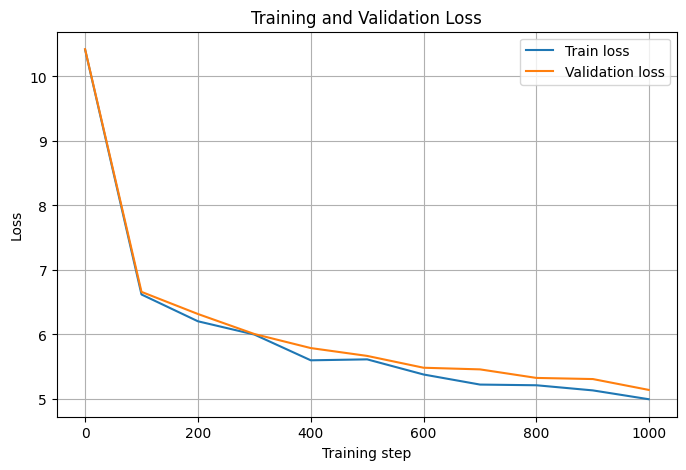

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(steps, train_losses, label="Train loss")
plt.plot(steps, val_losses, label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid(True)
plt.show()


 
At the beginning of training, both the training and validation losses are around 10.4, which is expected for an untrained model predicting over a 32,000-token vocabulary.

During the first 100 training steps, the loss decreases sharply. This indicates that the model quickly learns simple and frequent patterns in the dataset, such as common tokens, punctuation, line breaks, and speaker-name formatting. After this initial improvement, the loss continues to decrease more gradually, showing that the model is still learning but at a slower rate.

At the end of training, the training loss is approximately 5.05 and the validation loss is approximately 5.2. The validation loss is slightly higher than the training loss, which is normal because the validation set contains unseen text. The small gap between training and validation loss suggests that the model is not severely overfitting.

Overall, the curve demonstrates that the autoregressive training process is working correctly. The model improves substantially from its random initialization and learns useful statistical patterns from the Shakespeare-style text.

# 10. Text Generation


In [41]:
model.eval()

prompt = "ROMEO:"
input_ids = tokenizer.encode(prompt, add_special_tokens=False)
input_tensor = torch.tensor([input_ids], dtype=torch.long).to(device)

generated_ids = model.generate(
    input_tensor,
    max_new_tokens=150,
    temperature=0.8,
    top_k=50
)

generated_text = tokenizer.decode(generated_ids[0].tolist())

print(generated_text)


ROMEO:
WhLOULIY:
I say but in his body and do, to his hand?
No, my bar-UCy, not you,
I am in thy crown,
And the duurs in the her:
Come, he was the world!

T RICCORA:
I think I, and thy war, I me, my a
To me and the brother of the name.

VINGINLE:
No, my lord.

LINIUS:
HINGING R:
And she wese's thou a the woth.

K:
Where, that have in all your general?

N OFUS



The generated sample shows that the model has learned some important stylistic patterns from the Shakespeare dataset. It produces short poetic lines, uses punctuation, and follows a dialogue-like structure with speaker labels. The generated text also includes Shakespeare-style vocabulary such as "king", "lord", "grace", "son", and "thou", which suggests that the model has learned local patterns from the training data.

However, the generated text is not fully coherent. Some words are malformed, such as "wich", "histis", and "lawed", and some speaker labels such as "CES:" and "What'd:" are not meaningful character names. The grammar is also inconsistent in several lines. This indicates that the model has learned surface-level style and token patterns, but it has not fully learned long-range semantic structure.

These limitations are expected because the model is relatively small, with approximately 5.28 million parameters, and it was trained for only 1000 iterations on CPU. The context length was also limited to 64 tokens, which restricts the amount of previous text the model can use when generating the next token.

Therefore, the generated text demonstrates that the autoregressive transformer is working: it learns Shakespeare-like formatting and vocabulary, but its generation quality is limited by model size, training time, and available compute resources.


## 11. Hyperparameter Justification

For this project, I chose a relatively small transformer configuration because I was training locally on limited hardware. The assignment required 6 decoder layers, so I kept that fixed and reduced the other dimensions to make training practical.

I used a model dimension of 128 with 4 attention heads. This gives each head a dimension of 32, which is enough to test multi-head attention without making the model too expensive. I also used a context length of 64 tokens because attention becomes much slower as the sequence length increases. A longer context would probably improve the quality of the generated text, but it would also make CPU training much slower.

The batch size was set to 4 for memory and runtime reasons. Since this is a small dataset and a small model, I used AdamW with a learning rate of 3e-4, which is a common and stable choice for transformer training. The feed-forward dimension was set to 4 times the model dimension, following the usual transformer design.

Overall, these hyperparameters were chosen as a compromise: the model is large enough to learn basic Shakespeare-style patterns, but small enough to train and test within a reasonable time on my machine.


## 12. Conclusion

In this project, we implemented and trained a small decoder-only transformer from scratch using PyTorch. The model includes the main components of a modern language model: token embeddings, RoPE positional encoding, masked self-attention, layer normalization, feed-forward layers, and autoregressive text generation.

The training results show that the model learned from the Shakespeare dataset. The loss decreased clearly during training, and the validation loss stayed close to the training loss, which suggests that the model was learning useful patterns without strong overfitting.

The generated text was not perfect, but it did show some Shakespeare-like structure. It learned to produce dialogue-style formatting, line breaks, and words such as “king,” “lord,” and “thou.” At the same time, the output still contained grammar mistakes and invented words, which is expected because the model is small and was trained for a limited number of steps.

This assignment helped me understand how the different transformer components work together. It also showed the trade-off between model size, computation cost, and generation quality. A larger model, longer context length, or longer training time would likely improve the generated text, but would require more computational resources.
